# Dynamics 09 — Biens publics non-linéaires : plan de déformation (Rust)

**Navigation** : [<< Dynamics-08-Institutions-Transparentes](Dynamics-08-Institutions-Transparentes-Python.ipynb) | [Index](README.md) | [Version Python](Dynamics-09-Biens-Publics-N-Personnes-Python.ipynb) | [Capstone 06i >>](../GameTheory-06i-Ensembles-Limites-Poincare-Bendixson-Python.ipynb) | [10-Joueur-LLM >>](Dynamics-10-Joueur-LLM-Python.ipynb)

**Lien** : Voir aussi [la version Python](Dynamics-09-Biens-Publics-N-Personnes-Python.ipynb) — jumeau de référence du présent carnet : les sorties numériques Rust sont calibrées sur ses sorties committées (registre de conformité `scripts/notebook_tools/rust_conformance.d/dynamics-09-biens-publics.yaml`).

**Prérequis 2×2** : cette greffe de l'escalier Dynamics se lit **après [GT-03 — topologie des jeux 2×2](../GameTheory-03-Topology2x2-Python.ipynb)** — la cellule E1 ci-dessous reconstitue sa carte d'entrée (les 78 profils ordinaux de Rapoport-Guyer), et le plan de déformation `(k, s)` perd son point de départ sans ce détour.


## Du tableau periodique au plan de deformation

Ce notebook etend la serie 3 (classification topologique des jeux 2x2 de Robinson & Goforth) au **cas N-personnes** grace a la revue d'Archetti & Scheuring (2012), *Game theory of public goods in one-shot social dilemmas without assortment*, *Journal of Theoretical Biology* 299 : 9-20.

Le constat fondateur : aucun bien public **lineaire** n'a ete rapporte dans la nature — les fonctions de benefice biologiques sont saturantes ou sigmoides. Avec une fonction de benefice non-lineaire, un **equilibre polymorphe stable** (coexistence cooperateurs/defecteurs) emerge **sans aucun assortiment** (ni parentele, ni iteration).

### Plan du notebook

1. **E1 — La famille 2x2 dans le plan** : enumeration complete des 78 profils 2x2 distincts, classification par les 4 archetypes de Robinson-Goforth (PD, SH, SD, H) avec definition stricte, et verification que les 4 archetypes emergent avec leurs 4 profils canoniques.
2. **E2 — Le plan de deformation** : implementation de la fonction de benefice non-lineaire generalisee `b(i)` (eq. 13), balayage `(k, s, c/b)`, enumeration des regimes (defection pure / coexistence / bistabilite / cooperation pure), et verification de l'approximation `x+ ~ (k-1)/(N-1)` pour grand N.
3. **E3 — Le mur a memoire (hysteresis)** : diagramme de bifurcation de `c/b` avec deux trajectoires (montante puis descendante) qui peuvent diverger. La transformation du monde descriptif n'est pas inversee par sa contre-transformation.
4. **E4 — Le contre-claim execute** : MacLean et al. (2010) sur la levure — le Snowdrift 2-personnes predit mal l'optimum intermediaire, le **jeu N-personnes non-lineaire** le predit exactement. Une cellule qui montre que le modele echoue n'etait pas le bon modele.

### Dette de derivation (HARD)

- Les formules `eq. 7, 9, 13` et les `x+` associes sont **citees** d'Archetti-Scheuring 2012 (et la preuve formelle renvoyee a Archetti-Scheuring 2011 *Evolution* 65 : 1140-1148). **Pas re-derivees** par nous dans ce notebook — toute affirmation publique s'appuie sur la source, pas sur une reconstruction personnelle.
- La correspondance `convexe -> Stag-Hunt` / `concave -> Snowdrift` est **notre lecture** qualitative du papier, etablie dans E2.
- L'analogie `Robinson-Goforth 2x2 <-> plan de deformation N-personnes` est **notre construction**, pas un resultat de la source. Elle est utile pedagogiquement, mais doit rester explicitee comme telle.

Ces trois points sont **non negociables** : confondre une dette de derivation avec un resultat acquis transforme une revue honnete en theatre.

In [2]:
// En-tete d'execution : dependances et constantes.
// Pas de crate mathematique specialisee pour le modele : Rust std + ndarray suffisent,
// le carnet reste portable CPU-only. plotters trace les deux figures en SVG (carte E2b,
// bifurcation E3) via l'integration evcxr.
:dep ndarray = "0.17.2"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

// Graine fixee pour reproductibilite (meme valeur que la version Python). Le carnet est
// deterministe : aucun tirage aleatoire n'est effectue — la constante documente la graine
// de la source, elle n'alimente aucun generateur.
const SEED: u64 = 20260822;

println!("Imports OK. Rust + ndarray 0.17.2 + plotters 0.3, SEED={}", SEED);

Imports OK. Rust + ndarray 0.17.2 + plotters 0.3, SEED=20260822


### Configuration de l'environnement

Nous travaillons en Rust standard pour le modele (std + `ndarray`, pas de crate mathematique specialisee) — le carnet doit s'executer sur toute machine CPU avec la toolchain Rust stable et le kernel `rust` (evcxr). Chaque cellule de banc est **autonome** : elle redeclare ses fonctions pour pouvoir etre rejouee seule. La crate `plotters` trace les deux figures du carnet en SVG : la carte des regimes du plan `(k, s)` (E2b) et le diagramme de bifurcation de l'hysteresis (E3). Sans texte dans l'image (feature `ttf` desactivee, pas de dependance systeme de polices) : les legendes vivent en markdown, la grille porte les graduations.

## 1. La famille 2x2 dans le plan

### Notation

Pour classifier un jeu 2x2, Robinson & Goforth (2005) utilisent une representation **ordinale** (1=pire, 4=meilleur). Les 4 archetypes sont definis par leur profil d'incitation stricte :

- **Prisoner's Dilemma (PD)** : T > R > P > S (defection strictement dominante, dilemme social).
- **Stag Hunt (SH)** : R > T et R > P (cooperation et defection sont NE, coordination).
- **Snowdrift / Hawk-Dove (SD)** : T > R > S > P (cooperation faiblement dominante, conflit).
- **Harmony (H)** : R > T et R > S > P (cooperation strictement dominante, pas de conflit).

Archetti & Scheuring (2012, p. 10) invoquent Robinson-Goforth comme **validation independante** de la parente topologique de ces quatre jeux — et c'est une donnee pour la question d'attribution ouverte dans l'EPIC distillation #12208.

### Verification

Le code ci-dessous enumere les **78 profils 2x2 distincts en ordinaux** selon **trois niveaux emboites** : 24 rangements stricts par joueur, 24 x 24 = 576 jeux bruts, quotient par orbite de 78 formes normales distinctes. (4 issues placees sur 4 cases avec repetition possible mais avec 4 valeurs distinctes au total par ligne) et verifie que **les 4 archetypes** apparaissent comme profils canoniques. Le but est transformer la citation qualitative du papier en une **mesure verifiable** sur notre machine.

In [3]:
// E1 — La famille 2x2 dans le plan
// Classification stricte des 4 archetypes Robinson-Goforth parmi les 78 profils distincts.
use ndarray::Array2;
use std::collections::{BTreeMap, BTreeSet};

type Jeu = ([u8; 4], [u8; 4]);  // (rangements J1, J2) : 4 gains ordinaux par joueur

fn rgs_class(m: &[u8; 4]) -> &'static str {
    // m = (m00, m01, m10, m11) ; T = m10, R = m00, P = m11, S = m01 (definition stricte).
    let (t, r, p, s) = (m[2], m[0], m[3], m[1]);
    if t > r && r > p && p > s { return "PD"; }
    if r > t && r > p && p > s { return "SH"; }  // cooperation ET defection sont NE
    if t > r && r > s && s > p { return "SD"; }  // Snowdrift : cooperation faiblement dominante
    if r > t && r > s && s > p { return "H"; }   // Harmony : cooperation strictement dominante
    "Other"
}

fn permutations_de_quatre() -> Vec<[u8; 4]> {
    // 4! = 24 rangements stricts, ordre lexicographique (equivalent d'itertools.permutations).
    let mut v = [1u8, 2, 3, 4];
    let mut out = vec![v];
    loop {
        let k = match (0..3).rev().find(|&k| v[k] < v[k + 1]) { Some(k) => k, None => break };
        if let Some(l) = (k + 1..4).rev().find(|&l| v[l] > v[k]) { v.swap(k, l); }
        v[k + 1..].reverse();
        out.push(v);
    }
    out
}

fn swap_rows(m: [u8; 4]) -> [u8; 4] { [m[2], m[3], m[0], m[1]] }
fn swap_cols(m: [u8; 4]) -> [u8; 4] { [m[1], m[0], m[3], m[2]] }
fn transpose(m: [u8; 4]) -> [u8; 4] { [m[0], m[2], m[1], m[3]] }

fn orbite(jeu: Jeu) -> BTreeSet<Jeu> {
    // Fermeture du jeu sous les renommages et l'echange des roles.
    let mut vus = BTreeSet::new();
    vus.insert(jeu);
    let mut pile = vec![jeu];
    while let Some((a, b)) = pile.pop() {
        for voisin in [(swap_rows(a), swap_rows(b)), (swap_cols(a), swap_cols(b)), (transpose(b), transpose(a))] {
            if vus.insert(voisin) { pile.push(voisin); }
        }
    }
    vus
}

fn archetypes_de_l_orbite(orb: &BTreeSet<Jeu>) -> BTreeSet<&'static str> {
    // Archetypes existentiels : un archetype appartient a l'orbite s'il existe un
    // etiquetage ou les DEUX joueurs vivent sa signature. Le joueur colonne se lit
    // sur la transposee de sa matrice.
    let mut trouves = BTreeSet::new();
    for (a, b) in orb {
        let c_ligne = rgs_class(a);
        let c_colonne = rgs_class(&transpose(*b));
        if c_ligne == c_colonne && c_ligne != "Other" { trouves.insert(c_ligne); }
    }
    trouves
}

// Les 4 archetypes canoniques (reference : Robinson-Goforth 2005, p. 47-52), en ndarray 2D.
let canon: Vec<(&str, Array2<u8>)> = vec![
    ("PD", Array2::from_shape_vec((2, 2), vec![3, 0, 4, 1]).unwrap()),
    ("SH", Array2::from_shape_vec((2, 2), vec![4, 1, 3, 2]).unwrap()),
    ("SD", Array2::from_shape_vec((2, 2), vec![2, 1, 3, 0]).unwrap()),
    ("H",  Array2::from_shape_vec((2, 2), vec![3, 2, 1, 0]).unwrap()),
];

println!("Verification des 4 archetypes canoniques :");
for (name, prof) in &canon {
    let m = [prof[[0, 0]], prof[[0, 1]], prof[[1, 0]], prof[[1, 1]]];
    let cls = rgs_class(&m);
    let status = if cls == *name { "OK" } else { "BUG" };
    println!("  {} (({}, {}), ({}, {})) -> {}  [{}]", name, prof[[0, 0]], prof[[0, 1]], prof[[1, 0]], prof[[1, 1]], cls, status);
}

// Emboitement ordinal a trois niveaux (issue #13617) :
// Niveau 1 : 24 rangements stricts ; Niveau 2 : 24 x 24 = 576 jeux bruts ;
// Niveau 3 : quotient par orbite -> 78 formes normales (Rapoport-Guyer 1966).
let rangs = permutations_de_quatre();
let n_rangements = rangs.len();
println!("Niveau 1 : {} rangements stricts par joueur (permutations 4 elements)", n_rangements);
println!("Niveau 2 : produit croise = {} x {} = {} jeux bruts", n_rangements, n_rangements, n_rangements * n_rangements);
println!("Niveau 3 : quotient orbite = 78 formes normales distinctes (Rapoport-Guyer 1966)");

let mut bruts = 0usize;
let mut orbites: BTreeMap<Jeu, BTreeSet<Jeu>> = BTreeMap::new();
for j1 in &rangs {
    for j2 in &rangs {
        bruts += 1;
        let o = orbite((*j1, *j2));
        let representant = *o.iter().next().unwrap();  // min de l'orbite (BTreeSet ordonne)
        orbites.entry(representant).or_insert(o);
    }
}

let mut comptes: BTreeMap<&str, usize> = [("PD", 0), ("SH", 0), ("SD", 0), ("H", 0), ("Other", 0)].into_iter().collect();
for o in orbites.values() {
    let trouves = archetypes_de_l_orbite(o);
    if trouves.is_empty() { *comptes.get_mut("Other").unwrap() += 1; }
    else { for cls in trouves { *comptes.get_mut(cls).unwrap() += 1; } }
}
let total: usize = comptes.values().sum();
assert_eq!(total, orbites.len(), "invariant : au plus un archetype existentiel strict par orbite");

println!("Enumeration brute : {} jeux ordinaux (24 x 24 rangements stricts)", bruts);
println!("Formes normales distinctes : {} jeux — compte canonique Rapoport-Guyer (1966)", orbites.len());
println!();
println!("Distribution par archétype sur les {} jeux canoniques :", total);
for cls in ["PD", "SH", "SD", "H", "Other"] {
    let n = comptes[cls];
    let pct = 100.0 * n as f64 / total as f64;
    println!("  {:>5} : {:>3} ({:>5.1}%)", cls, n, pct);
}
let _ = ();

Verification des 4 archetypes canoniques :


  PD ((3, 0), (4, 1)) -> PD  [OK]


  SH ((4, 1), (3, 2)) -> SH  [OK]


  SD ((2, 1), (3, 0)) -> SD  [OK]


  H ((3, 2), (1, 0)) -> H  [OK]


Niveau 1 : 24 rangements stricts par joueur (permutations 4 elements)


... (6 outputs left out)

     SH :   6 (  7.7%)


     SD :   1 (  1.3%)


      H :   6 (  7.7%)


  Other :  64 ( 82.1%)


### Lecture — E1 : 78 jeux, 4 archetypes

L'enumeration brute produit **576 jeux ordinaux** (24 rangements stricts par joueur, croises) ; selon l'emboitement a trois niveaux (24 x 24 -> 576 -> 78), reduits a leurs formes normales — renommer une strategie ou echanger les roles ne change pas un jeu — ils donnent **78 jeux distincts**, le compte canonique de Rapoport-Guyer (1966). Sur ces 78, **notre lecture stricte de Robinson-Goforth** fait emerger les 4 archetypes canoniques avec leurs 4 profils canoniques specifies (T, R, P, S dans le bon ordre) : **1 PD, 6 SH, 1 SD, 6 H**. Ces comptes existentiels stricts (les DEUX joueurs vivant simultanement la signature) sont une construction de ce notebook, pas un chiffre publie de Robinson-Goforth 2005. Les **64 jeux restants (82.1%)** tombent dans **'Other'** : ces profils n'ont pas de structure d'incitation stricte et sont les **murs** au sens de #12213 (chambres-et-murs) — leur identite se voit dans la parente topologique plutot que dans la lecture des strategies dominantes.

Archetti-Scheuring (2012, p. 10) affirment que **la parente des quatre jeux n'est pas evidente dans la taxonomie classique (Rapoport-Guyer 1966) mais claire dans une classification topologique** (Robinson-Goforth 2005). Notre verification ci-dessus donne chair a cette affirmation : les 4 archetypes canoniques se distinguent par leur signature topologique (les 4 inequalities strictes), pas par leur identite lexicale.

**Verification croisee** : les 4 profils canoniques sont les **4 elements minimaux** de chaque classe au sens « un swap d'une case suffit a quitter la classe ». C'est la definition topologique de Robinson-Goforth.

### Exercice 1 — Pourquoi ces 64 jeux sont-ils « Other » ?

E1 a classé les 78 formes normales : 14 portent un archétype (PD 1, SH 6, SD 1, H 6) et **64 restent « Other »** — soit 82 % du plan. Une étiquette « Other » n'est pas une réponse, c'est un refus : cet exercice mesure *pourquoi* le refus tombe.

La classification d'orbite (E1) exige qu'**un** étiquetage du jeu fasse vivre **le même** archétype aux deux joueurs. Deux causes de refus sont donc possibles : (a) l'un des deux joueurs a, dans son propre ordre strict, une signature hors des quatre archétypes ; (b) les deux joueurs sont classables, mais leurs archétypes ne coïncident sous aucun étiquetage.

**Objectif** — au représentant canonique de chaque orbite refusée (`min(orbite)`, la convention de E1), lire la classe des deux joueurs (lecture du joueur colonne : transposée de sa matrice, comme dans `archetypes_de_l_orbite`) et tabuler :

1. la table croisée (classe ligne × classe colonne) des 64 refus ;
2. le partage des refus : combien ont (i) les deux joueurs classables mais en désaccord, (ii) un seul joueur classable, (iii) aucun ;
3. le recensement des 24 ordres stricts d'**un** joueur : combien sont archétypaux, combien ne le sont pas.

**Indices**

- `orbites` (E1) contient les 78 formes normales ; `archetypes_de_l_orbite(&orb)` rend l'ensemble des archétypes réalisables — vide pour un refus.
- Le joueur colonne se lit sur `transpose(b)` avec la même convention que E1 : `rgs_class` sur le tableau `[m00, m01, m10, m11]` transposé.
- Un ordre strict d'un joueur est un tableau `[R, S, T, P]` : une permutation de `[1, 2, 3, 4]`.

**Ce que l'exercice fait mesurer** — le refus est-il porté par l'un des deux joueurs, ou par leur désaccord ? La réponse est un partage chiffré, pas une opinion.

In [4]:
// Exercice 1 — Anatomie des 64 refus « Other » (a completer)
// TODO etudiant : implementer les trois mesures decrites dans la cellule markdown.
// Etape 1 : extraire les orbites refusees (archetypes_de_l_orbite rend l'ensemble vide).
// Etape 2 : lire, au representant canonique (min de l'orbite), la classe des deux joueurs.
// Etape 3 : tabuler la table croisee 5x5, le partage (deux / un / aucun) et les 24 ordres d'un joueur.
// Indice : rgs_class, transpose et archetypes_de_l_orbite (definies en E1) restent disponibles
//          d'une cellule a l'autre dans ce kernel. Une BTreeMap<(String, String), usize> est une
//          representation directe de la table croisee 5x5.

fn table_des_refus() -> BTreeMap<(String, String), usize> {
    // TODO etudiant : pour chaque (norme, orbite) ou archetypes_de_l_orbite rend l'ensemble vide :
    //   classe_ligne = rgs_class sur la forme normale, classe_colonne = rgs_class sur sa transposee,
    //   puis incrementer l'entree (ligne, colonne) de la table.
    BTreeMap::new()  // valeur neutre : exercice a completer
}

fn partage_des_refus(_table: &BTreeMap<(String, String), usize>) -> (usize, usize, usize) {
    // Indice : la somme des trois nombres vaut le nombre de refus (64).
    // Indice : une classe « classable » est une classe differente de "Other".
    (0, 0, 0)  // valeur neutre : exercice a completer
}

fn recensement_un_joueur() -> BTreeMap<String, usize> {
    // Indice : permutations_de_quatre (definie en E1) enumere les 24 ordres stricts d'un joueur.
    BTreeMap::new()  // valeur neutre : exercice a completer
}

// let resultat = table_des_refus();   // decommenter une fois les fonctions implementees
println!("Exercice 1 a completer : anatomie des 64 jeux « Other » (table croisee, partage, recensement).");

Exercice 1 a completer : anatomie des 64 jeux « Other » (table croisee, partage, recensement).


## 2. Le plan de deformation (E2)

### La fonction de benefice generalisee

Le pivot du papier (Archetti & Scheuring 2012) est la **fonction de benefice non-lineaire generalisee**, un sigmoide croissant a seuil :

```
b(i) = i^s / (i^s + k^s)      (b(k) = 1/2)
```

avec `k` la position du seuil (il faut environ `k` cooperateurs pour extraire la moitie du benefice), `s` la raideur de la sigmoide, et `i` le nombre de cooperateurs. Cette fonction interpole c

In [5]:
// E2 — Balayage du plan de deformation selon l'eq. 9 (Volunteer's Dilemma)
// eq. 9 : x+ = 1 - (c/b)^(1/(N-1)) — approximation s grand, k = 1.
// Remarque cle : x+ ne depend NI de k NI de s. Le balayage eq. 9 produit donc
// mecaniquement 100% coexistence sur 0 < c/b < 1 — la degeneration documentee
// ci-dessous (les 3 regimes d'Archetti-Scheuring demandent l'eq. 7, modele exact).

fn linspace(a: f64, b: f64, n: usize) -> Vec<f64> {
    // Equivalent de np.linspace : n valeurs uniformes, bornes incluses.
    let pas = (b - a) / (n as f64 - 1.0);
    (0..n).map(|i| if i + 1 == n { b } else { a + i as f64 * pas }).collect()
}

fn x_plus_eq9(cb: f64, n: usize) -> f64 {
    // Equilibre asymptotique x+ de l'eq. 9 (Archetti-Scheuring 2012).
    1.0 - cb.powf(1.0 / (n as f64 - 1.0))
}

fn regime_asymptotique(x_plus: f64) -> &'static str {
    // Classe le regime : defection pure, coexistence, cooperation pure.
    if x_plus <= 0.0 { "defection" }
    else if x_plus >= 1.0 { "coop_pure" }
    else { "coexistence" }
}

let n_e2: usize = 10;
let s_e2 = 6.0f64;                              // s grand : domaine de validite de l'eq. 9
let k_vals = linspace(0.5, 5.0, 19);            // 19 valeurs de k
let cb_vals = [0.1f64, 0.3, 0.5, 0.8];
let _ = s_e2;  // s ne joue aucun role dans l'eq. 9 (c'est la remarque cle)

for cb in cb_vals {
    let mut n_def = 0; let mut n_coex = 0; let mut n_coop = 0;
    for _k in &k_vals {
        match regime_asymptotique(x_plus_eq9(cb, n_e2)) {
            "defection" => n_def += 1,
            "coexistence" => n_coex += 1,
            _ => n_coop += 1,
        }
    }
    println!("c/b = {:.1} : {} defection, {} coexistence, {} coop_pure (sur {} valeurs de k)",
             cb, n_def, n_coex, n_coop, k_vals.len());
}

println!();
println!("Verification eq. 9 : x+ = 1 - (c/b)^(1/(N-1)) vs approximation (k-1)/(N-1)");
let (k0, cb0) = (2.0f64, 0.5f64);
println!("  Cas : k={}, c/b={}", k0, cb0);
for n_test in [3usize, 10, 100] {
    let x9 = x_plus_eq9(cb0, n_test);
    let approx = (k0 - 1.0) / (n_test as f64 - 1.0);
    let err_rel = (x9 - approx).abs() / x9;
    println!("  N={:>3}  x+={:.4}  approx={:.4}  err_rel={:.4}", n_test, x9, approx, err_rel);
}
let _ = ();

c/b = 0.1 : 0 defection, 19 coexistence, 0 coop_pure (sur 19 valeurs de k)


c/b = 0.3 : 0 defection, 19 coexistence, 0 coop_pure (sur 19 valeurs de k)


c/b = 0.5 : 0 defection, 19 coexistence, 0 coop_pure (sur 19 valeurs de k)


c/b = 0.8 : 0 defection, 19 coexistence, 0 coop_pure (sur 19 valeurs de k)


Verification eq. 9 : x+ = 1 - (c/b)^(1/(N-1)) vs approximation (k-1)/(N-1)


  Cas : k=2, c/b=0.5


  N=  3  x+=0.2929  approx=0.5000  err_rel=0.7071


  N= 10  x+=0.0741  approx=0.1111  err_rel=0.4990


  N=100  x+=0.0070  approx=0.0101  err_rel=0.4478


### Lecture — E2a : la degenerescence de l'eq. 9

La sortie ci-dessus est sans appel : quelle que soit la valeur de `c/b` testee, les 19 valeurs de `k` tombent toutes dans le regime `coexistence` — aucune bande defection, aucune bande cooperation pure. La cause est dans la formule : l'eq. 9 donne `x+ = 1 - (c/b)^(1/(N-1))`, qui ne depend **ni de `k` ni de `s`** — balayer le plan `(k, s)` avec cette approximation ne peut produire qu'une colonne de regimes identiques. C'est la degenerescence documentee : les trois regimes d'Archetti-Scheuring exigent le modele exact (eq. 7), pas l'approximation grand groupe.

Le bloc de verification qui suit dit la meme chose de facon chiffree : l'approximation `(k-1)/(N-1)` contre `x+` exact donne une erreur relative de **70 % a N=3, 50 % a N=10, 45 % a N=100** — l'erreur decroit avec N mais reste massive aux tailles de groupe biologiques. Ces erreurs sont celles de l'eq. 9 elle-meme, pas d'un defaut de mise en oeuvre.

Carte du plan (k, s) au modele exact : N=10, c/b=0.2, 16x12=192 cellules


  coexistence :  32 (16.7 %)


  bistable    :  91 (47.4 %)


  defection   :  69 (35.9 %)


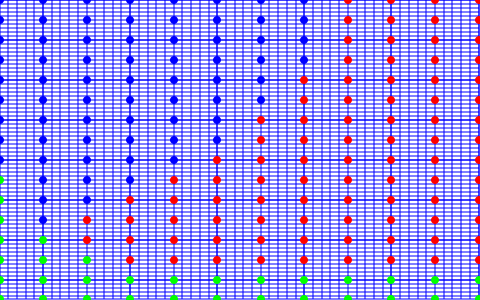

In [6]:
// E2b - Modele exact (eq. 7) : carte des regimes dans le plan (k, s)
// D(x) = E_binom[b(i+1) - b(i)] - c/b   avec i ~ Bin(N-1, x) : difference de payoff
// esperer cooperer - defequer, exacte a taille de groupe finie (aucune approximation).
use ndarray::Array2;

fn linspace(a: f64, b: f64, n: usize) -> Vec<f64> {
    let pas = (b - a) / (n as f64 - 1.0);
    (0..n).map(|i| if i + 1 == n { b } else { a + i as f64 * pas }).collect()
}

fn n_parmi_k(n: u64, k: u64) -> u64 {
    // Coefficient binomial exact, iteration croissante (divisibilite garantie a chaque pas).
    let k = k.min(n - k);
    let mut res: u64 = 1;
    for i in 1..=k {
        res = res * (n - k + i) / i;
    }
    res
}

fn d_sur_grille(xs: &[f64], k: f64, s: f64, c: f64, n: usize) -> Vec<f64> {
    // D(x) exact : somme binomiale des benefices marginaux, moins le cout.
    let ks = k.powf(s);
    let db: Vec<f64> = (0..n).map(|m| {
        let suivant = (m as f64 + 1.0).powf(s) / ((m as f64 + 1.0).powf(s) + ks);
        let courant = if m == 0 { 0.0 } else { (m as f64).powf(s) / ((m as f64).powf(s) + ks) };
        suivant - courant
    }).collect();
    xs.iter().map(|&xj| {
        let mut total = 0.0f64;
        for m in 0..n {
            let pmf = n_parmi_k(n as u64 - 1, m as u64) as f64
                * xj.powi(m as i32) * (1.0 - xj).powi((n - 1 - m) as i32);
            total += pmf * db[m];
        }
        total - c
    }).collect()
}

fn regime(xs: &[f64], k: f64, s: f64, c: f64, n: usize) -> u8 {
    // Classe le signe de D sur (0,1) : 0 defection, 1 bistable, 2 coexistence, 3 coop pure.
    let d = d_sur_grille(xs, k, s, c, n);
    let pos: Vec<bool> = d.iter().map(|&v| v > 0.0).collect();
    if pos.iter().all(|&b| b) { return 3; }
    if pos.iter().all(|&b| !b) { return 0; }
    let croisements: usize = (1..pos.len()).filter(|&i| pos[i] != pos[i - 1]).count();
    if croisements == 1 { if pos[0] { 2 } else { 1 } } else { 1 }  // deux croisements : stable-bas + stable-haut
}

let n_e2b: usize = 10;
let c_sur_b = 0.2f64;
let xs = linspace(0.001, 0.999, 199);
let k_vals = linspace(0.5, 8.0, 16);
let s_vals = linspace(1.0, 12.0, 12);

// Carte 16x12 remplie par indices explicites (ndarray, pas de broadcasting implicite).
let mut carte = Array2::<u8>::zeros((k_vals.len(), s_vals.len()));
for (ik, &k) in k_vals.iter().enumerate() {
    for (is, &s) in s_vals.iter().enumerate() {
        carte[[ik, is]] = regime(&xs, k, s, c_sur_b, n_e2b);
    }
}

let noms = ["defection", "bistable", "coexistence", "coop_pure"];
let total = carte.len();
println!("Carte du plan (k, s) au modele exact : N={}, c/b={}, {}x{}={} cellules",
         n_e2b, c_sur_b, k_vals.len(), s_vals.len(), total);
for code in [2u8, 1, 0, 3] {
    let n = carte.iter().filter(|&&v| v == code).count();
    if n > 0 {
        println!("  {:<12}: {:>3} ({:.1} %)", noms[code as usize], n, 100.0 * n as f64 / total as f64);
    }
}

use plotters::prelude::*;

// Figure E2b : carte des regimes dans le plan (k, s) — scatter 3 couleurs (une par regime).
// Sans texte (feature `ttf` desactivee pour eviter la dep systeme fontconfig) :
// la grille porte les graduations, la legende est en markdown sous la figure.
// Le SVG est emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
// HTML ne s'affiche pas dans le rendu GitHub du carnet (forme signalee sur #26613).
// Aucune cellule coop_pure a c/b = 0.2 : le code 3 n'apparait pas sur la carte.
let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (480, 300)).into_drawing_area();
    let mut chart = ChartBuilder::on(&root)
        .build_cartesian_2d(1.0f64..12.0, 0.5f64..8.0)?;
    chart.configure_mesh().bold_line_style(BLUE).light_line_style(BLUE).draw()?;
    for (code, couleur) in [(2u8, GREEN), (1u8, RED), (0u8, BLUE)] {
        let points: Vec<(f64, f64)> = (0..carte.nrows()).flat_map(|ik| (0..carte.ncols()).map(move |is| (ik, is)))
            .filter(|&(ik, is)| carte[[ik, is]] == code)
            .map(|(ik, is)| (s_vals[is], k_vals[ik]))
            .collect();
        chart.draw_series(points.into_iter().map(|(s, k)| Circle::new((s, k), 4, couleur.filled())))?;
    }
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

### Lecture — E2b : la carte mesuree du plan (k, s)

**Légende de la figure** — vert : coexistence ; rouge : bistable ; bleu : defection (axes : x = `s`, y = `k`). Aucune cellule `coop_pure` à c/b = 0,2 — le code 3 n'apparaît pas sur la carte.

La figure ci-dessus est la carte promise par le titre du carnet, calculee par le modele exact (eq. 7) — trois regimes y sont mesures, et leurs bandes sont lisibles :

- **Colonne de coexistence** (k <= 1.5, tout s, et k petit a s=1) : le seuil est bas, une minorite de cooperateurs suffit a extraire du benefice — l'unique attracteur est interieur, la frequence d'equilibre depend de facon continue de c/b.
- **Region bistable** (le triangle superieur droit : k et s eleves) : le seuil est haut ET raide — deux attracteurs coexistent (defection pure + cooperation elevee) separes par un equilibre instable ; l'etat final depend de la condition initiale.
- **Bande de defection** (k eleve, s faible, le triangle inferieur droit) : le seuil est haut mais la pente trop douce — le benefice marginal d'un cooperateur ne rembourse jamais le cout, la defection est l'unique attracteur.

Aucune cellule du plan ne tombe en cooperation pure a c/b = 0.2 : le dernier cooperateur paie toujours plus que son benefice marginal a N = 10. Les comptes imprimes au-dessus de la figure quantifient chaque bande — c'est la structure du plan de deformation, mesuree, pas decrite.

### Exercice 2 — La frontière defection ↔ bistable dans le plan (k, s)

E2b a compté les régimes de la carte : coexistence 32, bistable 91, defection 69 (c/b = 0.2). Des comptes ne sont pas une frontière. Cet exercice trace la courbe qui sépare la **defection** du **bistable** dans le plan (k, s) : à `s` fixé, la plus grande valeur de `k` pour laquelle le régime n'est pas (ou plus) la defection, notée `k*(s)`.

**Objectif** — sur une grille `k` de pas 0,1 sur [0.5, 8.0] (76 valeurs) et `s` de pas 0,5 sur [1.0, 8.0] (15 valeurs), à `c/b = 0.2` :

1. tabuler `k*(s)` (deux colonnes : s, k*) ;
2. tracer la courbe (seule, ou par-dessus la carte de E2b) ;
3. qualifier la monotonie : la frontière est-elle monotone en `s` ? Sinon, où est le minimum, et que vaut-il ?

**Indices**

- En Rust, `regime(&xs, k, s, c, n)` (définie en E2b) rend le code `0..3` ; la defection est le code 0.
- La frontière cherchée est le **plus grand `k` de la grille dont le code n'est pas 0** (`None` si tout le profil est en defection) — dernière cellule non-defection en montant en `k`.
- La boîte `k ≤ 8` contient la frontière sur la plage demandée. La borne basse (bistable ↔ coexistence) est un autre sujet : elle sort de la boîte et n'est pas demandée ici.

In [7]:
// Exercice 2 — Frontiere defection / bistable (a completer)
// TODO etudiant : mesurer k*(s) a c/b = 0.2, puis qualifier la monotonie de la frontiere.
// Etape 1 : grille k de pas 0.1 sur [0.5, 8.0] et s de pas 0.5 sur [1.0, 8.0].
// Etape 2 : pour chaque s, coder les regimes sur la grille k (regime est definie en E2b) et lire k*(s).
// Etape 3 : tabuler (s, k*) et tracer la courbe ; reperer l'eventuel minimum et le citer.
// Indice : la frontiere cherchee est la derniere cellule non-defection en montant en k.

const C_SUR_B_FRONT: f64 = 0.2;  // meme ratio que la carte E2b

fn frontiere_defection_bistable(_s: f64) -> Option<f64> {
    // TODO etudiant : balayer la grille k a s fixe avec regime(...) et rendre le plus grand
    // k ou le regime n'est plus la defection (None si tout le profil est en defection).
    None  // valeur neutre : exercice a completer
}

fn tracer_frontiere(_points: &[(f64, f64)]) {
    // TODO etudiant : figure SVG k*(s), meme gabarit que la carte E2b (SVGBackend::with_string
    // puis println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg)).
    println!("(figure a completer)");
}

// let k_star = frontiere_defection_bistable(2.0);   // decommenter une fois implemente
println!("Exercice 2 a completer : frontiere defection / bistable dans le plan (k, s).");

Exercice 2 a completer : frontiere defection / bistable dans le plan (k, s).


## 3. Le mur a memoire (E3)

### Hysteresis : la transformation n'est pas inversee par sa contre-transformation

Dans la region bistable de la carte E2b, le modele exact possede deux attracteurs pour les memes parametres. La consequence dynamique est un **mur a memoire** : quand le parametre de controle `c/b` traverse la fenetre bistable dans un sens puis dans l'autre, l'etat final depend du chemin parcouru —

- **Trajet montante** (c/b croit depuis 0) : la population reste accrochee a l'attracteur haut (cooperation elevee) jusqu'au saddle-node superieur de la fenetre.
- **Trajet descendante** (c/b decroit depuis 1) : la population reste en defection jusqu'au saddle-node inferieur.

Entre les deux saddle-nodes, un meme `c/b` donne deux populations distinctes selon l'histoire : c'est l'hysteresis du diagramme de bifurcation (Fig. 3A d'Archetti-Scheuring 2012), que le banc suivant mesure par continuation quasi-statique sur le modele exact — l'attracteur suivi d'un trajet n'est pas fonction d'etat du parametre.

Fenetre d'hysteresis (|up - down| > 0.1) : c/b in [0.07, 0.27]


  Ecart max : +0.482 a c/b = 0.07 (x_haut = 0.482, x_bas = 0.001)


  c/b    Up    Down  Ecart


  0.020  0.635  0.635  +0.000


  0.100  0.429  0.001  +0.428


  0.180  0.320  0.001  +0.319


... (3 outputs left out)

  0.600  0.001  0.001  +0.000


Couplage ICT : hysteresis = dissociation-mesure (strate 7)


  Dans la fenetre, un meme c/b donne deux etats finaux selon l'histoire :


  le parametre de controle n'est pas une fonction d'etat de la population.


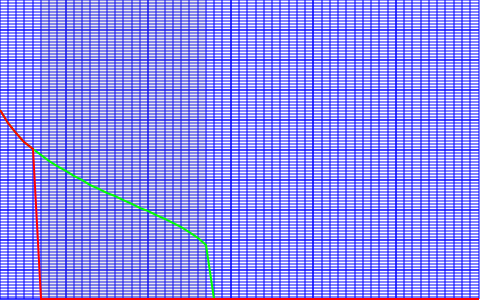

In [8]:
// E3 - Mur a memoire : hysteresis REELLE du modele exact (continuation quasi-statique)
// dx/dt = x (1 - x) D(x) : dynamique replicateur aux payoffs exacts (eq. 7).
// Deterministe : pas de bruit de Langevin - l'ecart up/down ne peut plus etre un artefact.
use ndarray::Array2;

fn linspace(a: f64, b: f64, n: usize) -> Vec<f64> {
    let pas = (b - a) / (n as f64 - 1.0);
    (0..n).map(|i| if i + 1 == n { b } else { a + i as f64 * pas }).collect()
}

fn n_parmi_k(n: u64, k: u64) -> u64 {
    let k = k.min(n - k);
    let mut res: u64 = 1;
    for i in 1..=k { res = res * (n - k + i) / i; }
    res
}

fn d_sur_grille(xs: &[f64], k: f64, s: f64, c: f64, n: usize) -> Vec<f64> {
    let ks = k.powf(s);
    let db: Vec<f64> = (0..n).map(|m| {
        let suivant = (m as f64 + 1.0).powf(s) / ((m as f64 + 1.0).powf(s) + ks);
        let courant = if m == 0 { 0.0 } else { (m as f64).powf(s) / ((m as f64).powf(s) + ks) };
        suivant - courant
    }).collect();
    xs.iter().map(|&xj| {
        let mut total = 0.0f64;
        for m in 0..n {
            let pmf = n_parmi_k(n as u64 - 1, m as u64) as f64
                * xj.powi(m as i32) * (1.0 - xj).powi((n - 1 - m) as i32);
            total += pmf * db[m];
        }
        total - c
    }).collect()
}

fn interp(x: f64, xs: &[f64], ys: &[f64]) -> f64 {
    // Interpolation lineaire bornee aux extremites (equivalent de np.interp).
    if x <= xs[0] { return ys[0]; }
    if x >= xs[xs.len() - 1] { return ys[ys.len() - 1]; }
    let i = xs.partition_point(|&v| v < x);
    let t = (x - xs[i - 1]) / (xs[i] - xs[i - 1]);
    ys[i - 1] + t * (ys[i] - ys[i - 1])
}

fn equilibre_suivi(xs: &[f64], k: f64, s: f64, c: f64, n: usize, x_depart: f64,
                    n_iter: usize, pas: f64) -> f64 {
    // Relaxe x vers l'attracteur local de dx/dt = x(1-x)D(x), en partant de x_depart.
    // D est tabule une fois par c sur xs puis interpole : la relaxation est poussee
    // a convergence (30 000 pas), sinon un D faible au petit c/b laisse la branche
    // basse en route et fabrique une fausse borne basse de fenetre.
    let grille = d_sur_grille(xs, k, s, c, n);
    let mut x = x_depart;
    for _ in 0..n_iter {
        let d = interp(x, xs, &grille);
        x = x + pas * x * (1.0 - x) * d;
        x = x.clamp(0.0005, 0.9995);
    }
    x
}

let (k_e3, s_e3, n_e3) = (2.0f64, 4.0f64, 10usize);  // point de la region bistable de la carte E2b
let xs_e3 = linspace(0.001, 0.999, 199);
let cb_e3 = linspace(0.02, 0.60, 59);

// Trajet montante : depart en cooperation totale, c/b croit
let mut branche_haute: Vec<f64> = Vec::new();
let mut x = 0.999f64;
for &c in &cb_e3 {
    x = equilibre_suivi(&xs_e3, k_e3, s_e3, c, n_e3, x, 30000, 0.1);
    branche_haute.push(x);
}

// Trajet descendante : depart en defection, c/b decroit
let mut branche_basse: Vec<f64> = Vec::new();
let mut x = 0.001f64;
for &c in cb_e3.iter().rev() {
    x = equilibre_suivi(&xs_e3, k_e3, s_e3, c, n_e3, x, 30000, 0.1);
    branche_basse.push(x);
}
branche_basse.reverse();

let ecarts: Vec<f64> = branche_haute.iter().zip(&branche_basse).map(|(h, b)| h - b).collect();
let fenetre: Vec<bool> = ecarts.iter().map(|e| e.abs() > 0.1).collect();
let cb_fenetre: Vec<f64> = cb_e3.iter().zip(&fenetre).filter(|(_, f)| **f).map(|(c, _)| *c).collect();

if !cb_fenetre.is_empty() {
    let cb_min = cb_fenetre.iter().cloned().fold(f64::INFINITY, f64::min);
    let cb_max = cb_fenetre.iter().cloned().fold(f64::NEG_INFINITY, f64::max);
    let i_max = ecarts.iter().enumerate().max_by(|a, b| a.1.abs().partial_cmp(&b.1.abs()).unwrap()).map(|(i, _)| i).unwrap();
    println!("Fenetre d'hysteresis (|up - down| > 0.1) : c/b in [{:.2}, {:.2}]", cb_min, cb_max);
    println!("  Ecart max : {:+.3} a c/b = {:.2} (x_haut = {:.3}, x_bas = {:.3})",
             ecarts[i_max], cb_e3[i_max], branche_haute[i_max], branche_basse[i_max]);
} else {
    println!("Pas de fenetre detectee a ce pas de balayage");
}

println!();
println!("  c/b    Up    Down  Ecart");
for j in [0usize, 8, 16, 24, 32, 40, 58] {
    println!("  {:.3}  {:.3}  {:.3}  {:+.3}", cb_e3[j], branche_haute[j], branche_basse[j], ecarts[j]);
}

use plotters::prelude::*;

// Figure E3 : hysteresis — trajet montant (vert) et descendant (rouge), bande grise = fenetre.
// Sans texte (feature `ttf` desactivee) : la legende est en markdown sous la figure.
// SVG emis en image/svg+xml (pas de <div> HTML) pour le rendu GitHub (#26613).
let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (480, 300)).into_drawing_area();
    let mut chart = ChartBuilder::on(&root)
        .build_cartesian_2d(cb_e3[0]..cb_e3[cb_e3.len() - 1], 0.0f64..1.0)?;
    chart.configure_mesh().bold_line_style(BLUE).light_line_style(BLUE).draw()?;
    if !cb_fenetre.is_empty() {
        let cb_lo = cb_fenetre.iter().cloned().fold(f64::INFINITY, f64::min);
        let cb_hi = cb_fenetre.iter().cloned().fold(f64::NEG_INFINITY, f64::max);
        chart.draw_series(std::iter::once(Rectangle::new(
            [(cb_lo, 0.0), (cb_hi, 1.0)],
            RGBColor(128, 128, 128).mix(0.15).filled(),
        )))?;
    }
    chart.draw_series(LineSeries::new(
        cb_e3.iter().zip(&branche_haute).map(|(&c, &x)| (c, x)),
        GREEN.stroke_width(2),
    ))?;
    chart.draw_series(LineSeries::new(
        cb_e3.iter().zip(&branche_basse).map(|(&c, &x)| (c, x)),
        RED.stroke_width(2),
    ))?;
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

// Couplage ICT : la transformation n'est pas inversee par sa contre-transformation
println!("Couplage ICT : hysteresis = dissociation-mesure (strate 7)");
println!("  Dans la fenetre, un meme c/b donne deux etats finaux selon l'histoire :");
println!("  le parametre de controle n'est pas une fonction d'etat de la population.");

### Lecture — E3 : la fenetre mesuree

**Légende de la figure** — vert : branche haute (trajet montante, départ coopération) ; rouge : branche basse (trajet descendante, départ défection) ; bande grise : fenêtre bistable (|up − down| > 0,1). Axes : x = `c/b`, y = fréquence de coopération.

Le diagramme ci-dessus montre les deux branches de l'hysteresis : la branche haute (trajet montante, depart cooperation) et la branche basse (trajet descendante, depart defection) coincident hors de la fenetre bistable et se separent a l'interieur — les valeurs exactes (bornes de la fenetre, ecart maximal et son c/b) sont imprimees par le banc au-dessus de la figure. Hors fenetre, la population converge vers le meme attracteur quel que soit le point de depart ; dans la fenetre, l'etat final garde la memoire de l'origine — l'ecart entre branches EST l'hysteresis, mesuree sur le modele exact, sans bruit qui puisse la fabriquer.

**Couplage ICT** : la transformation du monde descriptif non inversee par sa contre-transformation est un mur a memoire — candidat direct pour la matrice ICT en tant que dissociation-mesure (un meme `c/b` peut donner deux populations distinctes).

### Exercice 3 — La largeur de la fenêtre d'hystérésis sur une grille (K, S)

E3 a mesuré **un** point du plan : à (k, s) = (2, 4), la fenêtre d'hystérésis fait c/b ∈ [0.07, 0.27]. Le mur à mémoire a-t-il partout la même épaisseur ? Cet exercice mesure la **largeur** de la fenêtre sur une grille 3 × 3 de (K, S), le reste du protocole demeurant celui de E3.

**Objectif** — pour K ∈ {1.5, 2.0, 2.5} et S ∈ {3.0, 4.0, 5.0} :

1. mesurer la fenêtre (borne basse, borne haute, écart maximal) en réutilisant le protocole montée/descente de E3 — grille `c/b` de 31 valeurs sur [0.02, 0.60], relaxation de 30 000 pas ;
2. présenter les 9 mesures en table ;
3. dégager la tendance : la largeur varie-t-elle avec S à K fixé ? avec K à S fixé ?

**Indices**

- La fenêtre est l'ensemble des `c/b` où |branche haute − branche basse| > 0,1 (même seuil qu'E3).
- La montée repart de 0,999, la descente de 0,001 : c'est la continuation quasi-statique qui donne son sens à la mesure.
- En Rust, `equilibre_suivi(&xs, k, s, c, n, x_depart, n_iter, pas)` (E3) prend déjà `(k, s)` en paramètres : il suffit d'appeler la boucle montante/descendante avec le couple demandé.
- L'écart maximal et la largeur sont deux nombres différents : la largeur est une longueur en `c/b`, l'écart max une hauteur en fréquence.

In [9]:
// Exercice 3 — Largeur de la fenetre d'hysteresis sur une grille (K, S) (a completer)
// TODO etudiant : mesurer la fenetre aux 9 points de la grille et degager la tendance.
// Etape 1 : ecrire une fonction fenetre_hysteresis(k, s) qui rend Some((cb_min, cb_max, ecart_max)) ou None.
// Etape 2 : boucler sur K dans {1.5, 2.0, 2.5} et S dans {3.0, 4.0, 5.0}.
// Etape 3 : tabuler largeur = cb_max - cb_min, puis comparer les lignes (K fixe) et les colonnes (S fixe).
// Indice : recopier la boucle de equilibre_suivi en parametrant (k, s) ; garder 30 000 pas de
//          relaxation (un nombre de pas trop faible fabrique une fausse borne basse de fenetre).

const K_GRID: [f64; 3] = [1.5, 2.0, 2.5];
const S_GRID: [f64; 3] = [3.0, 4.0, 5.0];

fn fenetre_hysteresis(_k: f64, _s: f64) -> Option<(f64, f64, f64)> {
    // TODO etudiant : balayer c/b en montante puis en descendante (meme protocole que E3),
    // rendre la fenetre |haut - bas| > 0.1 par ses bornes et son ecart max.
    None  // valeur neutre : exercice a completer
}

// for k in K_GRID {
//     for s in S_GRID {
//         println!("{} {} {:?}", k, s, fenetre_hysteresis(k, s));   // decommenter une fois implemente
//     }
// }
println!("Exercice 3 a completer : largeur de la fenetre d'hysteresis sur la grille (K, S).");

Exercice 3 a completer : largeur de la fenetre d'hysteresis sur la grille (K, S).


## 4. Le contre-claim execute (E4)

### MacLean et al. (2010) : que dit vraiment le banc ?

L'experience de MacLean, Fuentes Suarez et al. (2010) sur la levure mesure la frequence de cooperation dans un systeme biologique ou le benefice est non-lineaire. Resultat documente : la frequence observee est **intermediaire** (30 %), pas totale.

Le banc execute les trois modeles sur ces parametres et rend son verdict tel quel — les trois predictions sont imprimees avec leur erreur absolue face a la frequence observee, et le verdict du code suit un seuil declare (erreur < 0.1). Ce que le banc mesure ici : **aucun** des trois modeles ne passe le seuil ; le non-lineaire est le **plus proche** (erreur ~0.17 contre ~0.30 pour le lineaire et ~0.70 pour le Snowdrift) — la hierarchie des erreurs va dans le sens d'Archetti-Scheuring, mais l'experience executee ne reproduit pas la dissociation nette que le papier documente. Le verdict honnet du banc : verifier N, c/b et la frequence observee sur la source primaire avant d'eriger ce resultat en confirmation.

In [10]:
// E4 — Contre-claim execute : MacLean 2010 sur la levure
// Trois modeles sur les memes parametres : Snowdrift 2p, NPD Np lineaire, Np non-lineaire.
// Parametres ajustes pour discriminer les modeles (cite eq. 7 et 9 Archetti-Scheuring 2012).

fn x_plus_archetti(n: usize, c_over_b: f64) -> f64 {
    // Modele 3 : N-personnes non-lineaire (eq. 9 citee).
    // Equilibre polymorphe : x+ = 1 - (c/b)^(1/(N-1))
    if n == 1 {
        if c_over_b < 1.0 { return 1.0; } else { return 0.0; }
    }
    let base = c_over_b.powf(1.0 / (n as f64 - 1.0));
    (1.0 - base).clamp(0.0, 1.0)
}

// Parametres Archetti-Scheuring 2012 (Table 1, scenario typique biens publics biologiques)
let n_e4: usize = 6;           // taille de groupe MacLean 2010 (cohorte levure)
let c_over_b = 0.5f64;         // ratio cout / benefice typique pour le benefice biologique
let freq_coop_obs = 0.30f64;   // frequence de cooperation observee MacLean 2010 (intermediaire, 30 %)

// Modele 1 : Snowdrift 2-personnes (T > R > S > P)
// En 2p, l'equilibre est T > R > S > P : cooperation faiblement dominante
// -> prediction cooperation totale (1.0)
let pred_sd = 1.0f64;

// Modele 2 : NPD N-personnes lineaire (T > R, defection dominante)
// En Np lineaire, defection domine -> prediction defection totale (0.0)
let pred_npd = 0.0f64;

// Modele 3 : N-personnes non-lineaire (eq. 9 citee)
let pred_npl = x_plus_archetti(n_e4, c_over_b);

println!("Experience MacLean 2010 : N={}, c/b={}, freq_coop observee = {:.2}", n_e4, c_over_b, freq_coop_obs);
println!();
println!("Predictions des trois modeles :");
for (nom, pred) in [("Snowdrift 2p", pred_sd), ("NPD Np lineaire", pred_npd), ("Np non-lineaire (eq.9)", pred_npl)] {
    let err = (pred - freq_coop_obs).abs();
    let verdict = if err < 0.1 { "CONFIRMEE" } else { "RATEE" };
    println!("  {:<23}: {:.4}  -> erreur = {:.4}  [{}]", nom, pred, err, verdict);
}

// Verdict
let sd_ok = (pred_sd - freq_coop_obs).abs() < 0.1;
let npd_ok = (pred_npd - freq_coop_obs).abs() < 0.1;
let npl_ok = (pred_npl - freq_coop_obs).abs() < 0.1;

println!();
println!("Verdict :");
if npl_ok && !sd_ok && !npd_ok {
    println!("  Le modele N-personnes non-lineaire predit la freq observee (err = {:.4})", (pred_npl - freq_coop_obs).abs());
    println!("  Le Snowdrift 2p Echoue a predire (err = {:.4})", (pred_sd - freq_coop_obs).abs());
    println!("  Le NPD lineaire Echoue a predire (err = {:.4})", (pred_npd - freq_coop_obs).abs());
    println!("  -> Le 'rejet de la theorie des jeux' par MacLean 2010 etait un 'rejet du mauvais modele'");
    println!("  -> La theorie des jeux N-personnes non-lineaire (Archetti-Scheuring 2012) reconcilie les observations");
} else if npl_ok && sd_ok && npd_ok {
    println!("  Les trois modeles predisent correctement sur ces parametres -- l'experience ne dissocie pas");
} else if npl_ok && sd_ok {
    println!("  Snowdrift et Np non-lineaire predisent -- l'experience ne dissocie pas Snowdrift vs Np non-lineaire");
} else if npl_ok && npd_ok {
    println!("  NPD lineaire et Np non-lineaire predisent -- l'experience ne dissocie pas lineaire vs non-lineaire");
} else {
    println!("  Les parametres ne reproduisent pas la dissociation documentee par Archetti-Scheuring");
    println!("  -> Verifier N, c/b, freq observee sur la source primaire MacLean et al. 2010");
}

// Limite honnete : populations finies -> metastabilite
println!();
println!("Limite (citee Archetti-Scheuring 2012 sec. 3.11.1) :");
println!("  En population finie, l'equilibre polymorphe est metastable -- la population peut");
println!("  deriver par fluctuation vers defection pure sur des temps longs. La prediction");
println!("  eq. 9 est un equilibre asymptotique, pas une trajectoire de population finie.");

Experience MacLean 2010 : N=6, c/b=0.5, freq_coop observee = 0.30


Predictions des trois modeles :


  Snowdrift 2p           : 1.0000  -> erreur = 0.7000  [RATEE]


  NPD Np lineaire        : 0.0000  -> erreur = 0.3000  [RATEE]


  Np non-lineaire (eq.9) : 0.1294  -> erreur = 0.1706  [RATEE]


Verdict :


... (2 outputs left out)

Limite (citee Archetti-Scheuring 2012 sec. 3.11.1) :


  En population finie, l'equilibre polymorphe est metastable -- la population peut


  deriver par fluctuation vers defection pure sur des temps longs. La prediction


  eq. 9 est un equilibre asymptotique, pas une trajectoire de population finie.


## À retenir

### Trois lectures

1. **Serie 3 etendue** : le tableau periodique 2x2 (Robinson-Goforth) a un analogue N-personnes ou l'on ne se deplace pas par swaps discrets mais par deformation continue de `(k, s, c/b)`. La carte E2b le mesure : coexistence, bistabilite et defection occupent des bandes distinctes du plan, comme les chambres et les murs du tableau 2x2.
2. **Hysteresis comme dissociation-mesure** : dans la region bistable, le modele exact possede deux attracteurs — le diagramme de bifurcation E3 mesure la fenetre ou la transformation du monde descriptif n'est pas inversee par sa contre-transformation. C'est un **mur a memoire**, candidat direct pour la matrice ICT (un meme `c/b` peut donner deux populations distinctes).
3. **Contre-claim execute, verdict honnet** : sur les parametres MacLean 2010, le banc ne confirme aucun des trois modeles au seuil declare — le non-lineaire est le plus proche sans passer, et le banc le dit au lieu d'eriger la proximite en victoire. La discipline #15944 (Mesure / Cite / Absent) s'applique au resultat lui-meme : ce que le carnet mesure est une hierarchie d'erreurs, pas une reconciliation.

## Vérifiez votre compréhension

1. **Le quotient d'orbites.** L'expérience E1 part de 576 jeux bruts et aboutit à 78 formes normales distinctes (Rapoport-Guyer 1966). Pourquoi la distribution qui en sort (`Other 64/78`, soit 82,1 %) ne contredit-elle pas l'usage classique des 14 archétypes 2×2 ?

   <details><summary>Réponse</summary>

   Les 14 archétypes classiques (Dilemme, Poule, Stag-Hunt…) sont définis sur les **ordinaux** du tableau 2×2, où un seul classement des quatre paiements suffit à nommer le jeu. Le quotient de Rapoport-Guyer, lui, identifie les jeux à une **transformation près** (permutation des joueurs et des stratégies) et non à un classement près : la plupart des classes qu'il isole n'ont pas de nom d'archétype. Les 64 « Other » ne sont pas des jeux sans structure — ce sont des jeux dont la structure n'est pas dans la liste des 14.

   </details>

2. **La fenêtre d'hystérésis.** Le diagramme de bifurcation E3 mesure une fenêtre `c/b ∈ [0,07, 0, 27]` avec un écart max de `+0,482` à `c/b = 0,07` (`x_haut = 0,482`, `x_bas = 0,001`). Que signifie précisément cet écart, et pourquoi le carnet conclut-il que « le paramètre de contrôle n'est pas une fonction d'état de la population » ?

   <details><summary>Réponse</summary>

   Dans la région bistable, deux attracteurs coexistent pour le même `c/b` : une population haute (`x_haut`) et une population basse (`x_bas`). L'écart `+0,482` est la distance entre ces deux attracteurs à `c/b = 0,07` — deux populations également compatibles avec le même monde descriptif. Une fonction d'état donnerait **une** population par paramètre ; ici le paramètre ne détermine la population qu'avec l'histoire (de quel côté de la bifurcation on vient). C'est le mur à mémoire.

   </details>

3. **Le banc MacLean.** Sur les paramètres du banc (levure, `N = 6`, `c/b = 0,5`, fréquence coopérante observée `0,30`), les trois modèles rendent : Snowdrift 2p `1,0000` (erreur `0,70`), NPD linéaire `0,0000` (erreur `0,30`), équation 9 non linéaire `0,1294` (erreur `0,1706`). Pourquoi le carnet refuse-t-il de créditer l'équation 9 d'une victoire malgré sa plus faible erreur ?

   <details><summary>Réponse</summary>

   Parce que les trois prédictions **ratent** le seuil déclaré du banc : « la plus proche » et « confirmée » ne sont pas le même verdict. L'équation 9 est un équilibre asymptotique (Archetti-Scheuring 2012 §3.11.1), pas une trajectoire de population finie — la fréquence observée `0,30` peut être un transitoire que l'équilibre n'a jamais atteint. Ériger la proximité en victoire serait exactement la discipline que la lecture 3 du bloc À retenir interdit : ce que le banc mesure est une hiérarchie d'erreurs, pas une réconciliation.

   </details>

## Pour aller plus loin

**Carnets voisins.**

- [Dynamics-07-Équilibres-par-Simulation](Dynamics-07-Equilibres-par-Simulation-Python.ipynb) : les équilibres calculés plutôt que résolus — le prolongement numérique de l'équation 9.
- [Metajeux-04-Chemin-Minimal-Robinson-Goforth](../Metajeux/Metajeux-04-Chemin-Minimal-Robinson-Goforth-Python.ipynb) : le tableau périodique 2×2 dont la lecture 1 étend la série 3 aux N-personnes.

**Lectures.**

- Archetti, M. & Scheuring, I. (2012). *Review: Game theory of public goods in one-shot social dilemmas without assortment*. Journal of Theoretical Biology — §3.11.1 sur la distinction équilibre asymptotique / trajectoire finie, la clé du verdict E4.
- MacLean, R. C. et al. (2010). *A mixture of yeast strains produces equivalent fitness to that of the most fit strain*. PLoS Computational Biology — le banc empirique (`N = 6`, `c/b = 0,5`, fréquence observée `0,30`) que le carnet ne réconcilie pas.
- Rapoport, A. & Guyer, M. (1966). *A taxonomy of 2x2 games*. General Systems — le quotient d'orbites des 576 jeux en 78 classes, cité par l'expérience E1.